In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/My Drive/2Tresample_data.csv')

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Conv1D, Flatten
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [ ]:
# Drop the timestamp column if it's not needed for prediction
df = df.drop(columns=['timestamp',  'Severity', 'Hours_till_Failure'])

# Split the data into features and target
X = df.drop(columns=['Failure'])  # Use the 'Failure' column as the target for classification
y = df['Failure']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape X for GRU input (samples, timesteps, features)
# Choosing timesteps (e.g., 10)
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y.iloc[i + timesteps])  # Original target values for classification

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
# Build the hybrid TCN-GRU model
model = Sequential([
    # TCN part
    Conv1D(filters=32, kernel_size=2, padding='causal', activation='relu', dilation_rate=1, input_shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=2),

    # GRU part
    GRU(units=64, return_sequences=True),
    Dropout(0.2),
    GRU(units=32),
    Dropout(0.2),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Output layer for regression
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 10, 32)              │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 10, 64)              │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ (None, 10, 64)              │          24,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 41,697 (162.88 KB)

 Trainable params: 41,697 (162.88 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Fit the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 46s 25ms/step - accuracy: 0.9875 - loss: 0.0458 - val_accuracy: 0.9959 - val_loss: 0.0094
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 39s 24ms/step - accuracy: 0.9959 - loss: 0.0104 - val_accuracy: 0.9970 - val_loss: 0.0071
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 39s 24ms/step - accuracy: 0.9970 - loss: 0.0081 - val_accuracy: 0.9934 - val_loss: 0.0118
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 42s 24ms/step - accuracy: 0.9966 - loss: 0.0086 - val_accuracy: 0.9985 - val_loss: 0.0057
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 43s 25ms/step - accuracy: 0.9970 - loss: 0.0076 - val_accuracy: 0.9987 - val_loss: 0.0051
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.9974 - loss: 0.0070 - val_accuracy: 0.9985 - val_loss: 0.0053
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 44s 25ms/step - accuracy: 0.9974 - loss: 0.0072 - val_accuracy: 0.9986 - val_loss: 0.0059
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.9973 -

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss}, Test Accuracy: {test_accuracy}')

# Predict the classes on the test set
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to class labels

# Import metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate additional metrics
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'micro', 'macro', or 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')
f1 = f1_score(y_test, y_pred_classes, average='weighted')

# Print the metrics
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

791/791 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9988 - loss: 0.0034
Test Loss: 0.0035052262246608734, Test Accuracy: 0.9990119934082031
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Precision: 0.9990
Recall: 0.9990
F1-Score: 0.9990


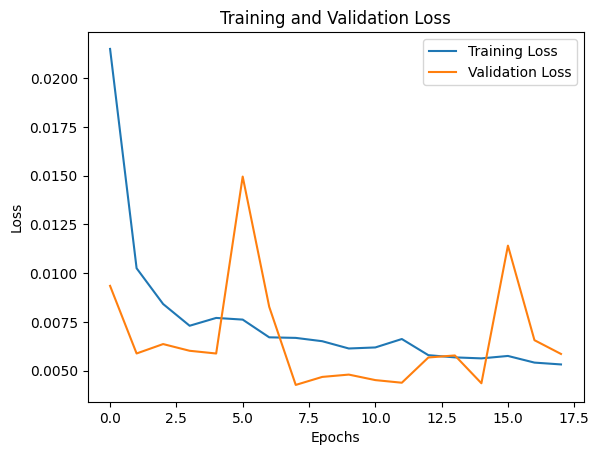

In [ ]:
# Plotting the training and validation loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

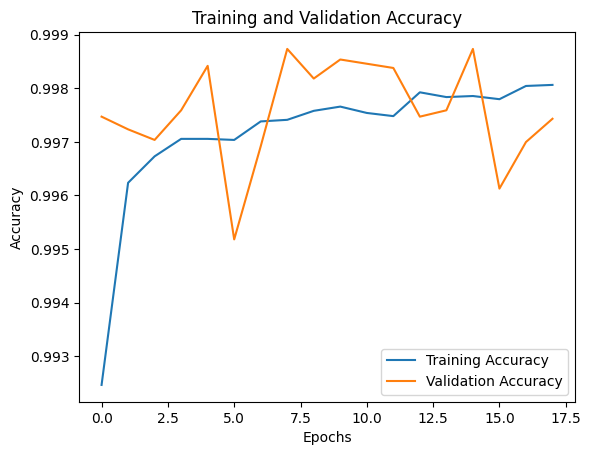

In [ ]:
# Plotting accuracy if needed
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Drop 'timestamp' column
df = df.drop(['timestamp'], axis=1)

In [ ]:
# Split the data into features and target
X = df.drop(columns=['Hours_till_Failure'])
y = df['Hours_till_Failure']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape y to a 2D array for scaling
y_2d = y.values.reshape(-1, 1)  # Reshape to (n_samples, 1)
y_scaled = scaler.fit_transform(y_2d)  # Now you can scale y
y_scaled = y_scaled.ravel()  # Convert back to 1D after scaling if needed

# Reshape X for TCN input (samples, timesteps, features)
# Here, you can choose the number of timesteps. A common choice is 10.
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y_scaled[i + timesteps])  # Use the scaled y values

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
# Build the hybrid TCN-GRU model
model = Sequential([
    # TCN part
    Conv1D(filters=32, kernel_size=2, padding='causal', activation='relu', dilation_rate=1, input_shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=2),

    # GRU part
    GRU(units=64, return_sequences=True),
    Dropout(0.2),
    GRU(units=32),
    Dropout(0.2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Print model summary
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 32)         │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 10, 64)         │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,825 (163.38 KB)

 Trainable params: 41,825 (163.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# Fit the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - loss: 0.4616 - val_loss: 0.2606
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 51s 28ms/step - loss: 0.2706 - val_loss: 0.2136
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 72s 21ms/step - loss: 0.2248 - val_loss: 0.1792
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - loss: 0.1956 - val_loss: 0.1766
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 42s 21ms/step - loss: 0.1841 - val_loss: 0.1704
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 39s 20ms/step - loss: 0.1695 - val_loss: 0.1514
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - loss: 0.1627 - val_loss: 0.1511
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - loss: 0.1525 - val_loss: 0.1295
Epoch 9/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - loss: 0.1479 - val_loss: 0.1359
Epoch 10/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - loss: 0.1418 - val_loss: 0.1322
Epoch 11/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - loss: 0.1399 - val_loss: 0.1446
Epoch 12

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
# Evaluate the model on the test data
test_loss = model.evaluate(X_test, y_test)
print(f'Test Loss (Mean Squared Error): {test_loss}')

# Predicting on the test set
y_pred = model.predict(X_test).flatten()  # Flattening to match true labels' shape

# Evaluate with MAE and R² Score
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R² Score: {r2}")

791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0748
Test Loss (Mean Squared Error): 0.07303740829229355
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
Mean Absolute Error (MAE): 0.1744660683384866
R² Score: 0.9275986120670408


In [ ]:
# Reshape for inverse_transform
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_original = scaler.inverse_transform(y_pred.reshape(-1, 1)).flatten()

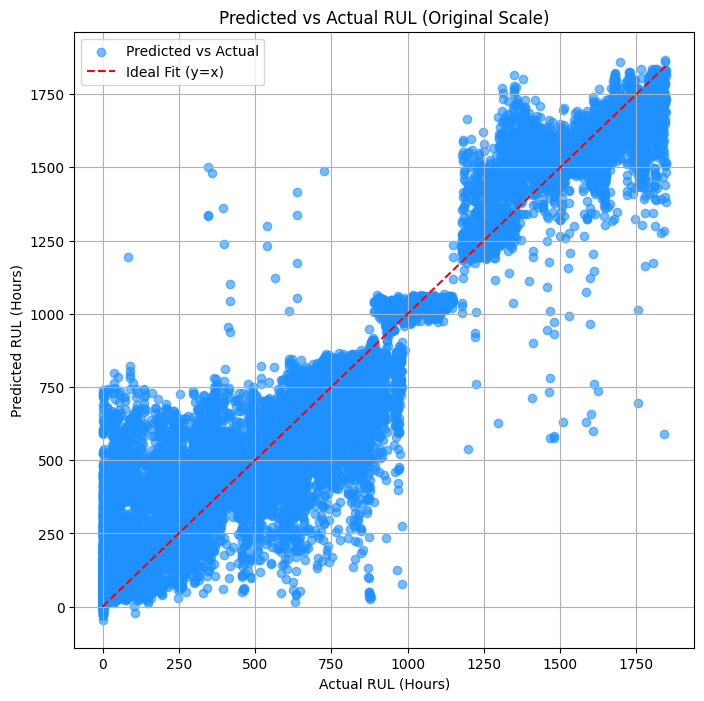

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 8))

plt.scatter(y_test_original, y_pred_original, color='dodgerblue', alpha=0.6, label='Predicted vs Actual')
plt.plot(
    [min(y_test_original), max(y_test_original)],
    [min(y_test_original), max(y_test_original)],
    color='red', linestyle='--', label='Ideal Fit (y=x)'
)

plt.xlabel('Actual RUL (Hours)')
plt.ylabel('Predicted RUL (Hours)')
plt.title('Predicted vs Actual RUL (Original Scale)')

plt.legend()
plt.grid(True)
plt.show()


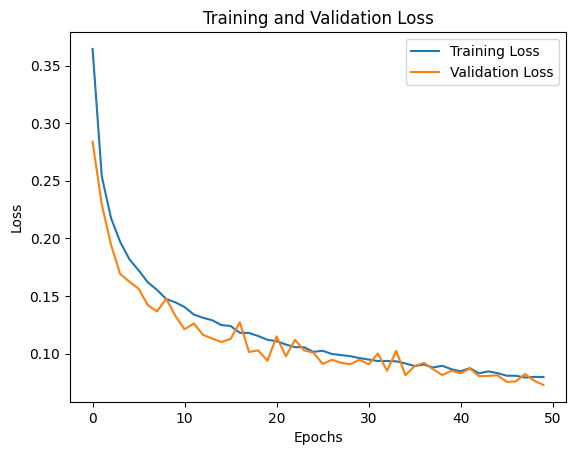

In [ ]:
import matplotlib.pyplot as plt
# Plotting the loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()